STEP 1: Create a 2-qubit circuit
Initial state is |00>

     
q_0: 
     
q_1: 
     
c: 2/
     

STEP 2: Apply Hadamard gate to control qubit
H|0> = (|0> + |1>)/√2 → puts control qubit into superposition



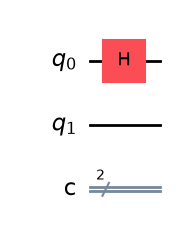


STEP 3: Apply CNOT gate (control=0, target=1)
Creates entanglement between control and target qubits



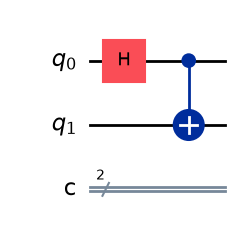


STEP 4: Statevector after H + CNOT

Statevector:
Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))

STEP 5: Reduced Bloch Sphere for each qubit
Each qubit individually is mixed due to entanglement → vector at center



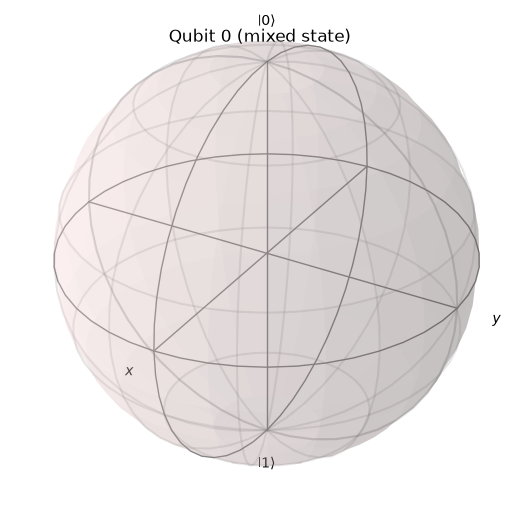

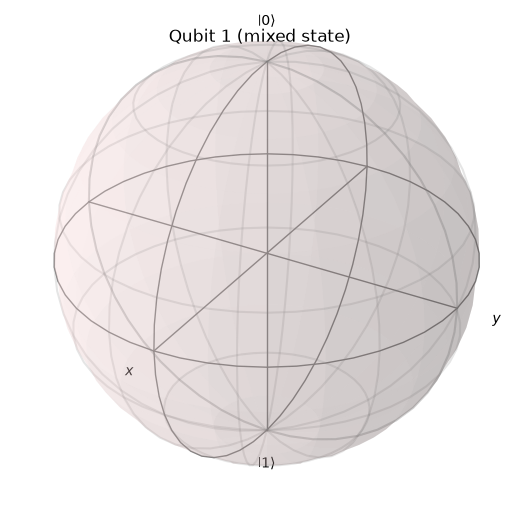


STEP 6: Measurement



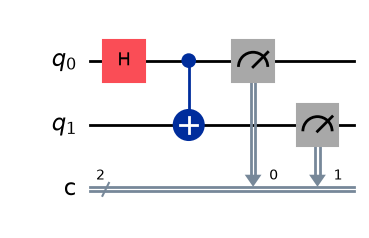


STEP 7: Run Simulation (1024 shots)

Measurement Results:
{'00': 519, '11': 505}


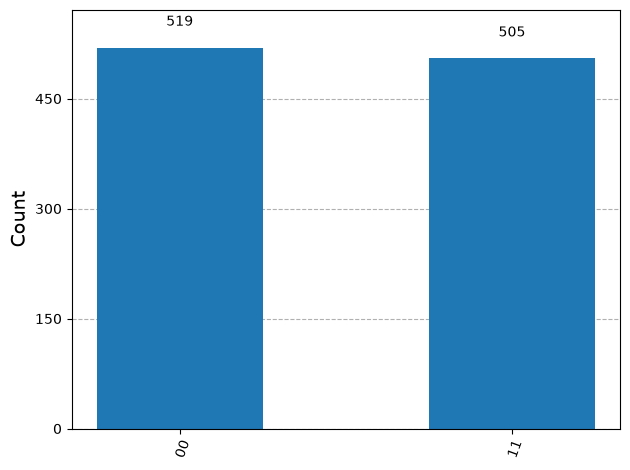


FINAL INTERPRETATION:
Hadamard on control qubit puts it into superposition
CNOT entangles control and target qubits → Bell state |Φ+> = (|00> + |11>)/√2
Measurement yields ~50% |00> and ~50% |11>
Reduced Bloch spheres show each qubit as completely mixed (vector at center)


In [1]:
# ============================================================
# FULL Controlled-NOT (CNOT) Gate Demonstration
# Includes:
#  - Circuit diagram
#  - Statevector
#  - Bloch sphere visualization (reduced qubits)
#  - Measurement histogram
# ============================================================

%matplotlib inline

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector, partial_trace
from qiskit.visualization import plot_histogram, plot_bloch_vector
from matplotlib import pyplot as plt

print("====================================")
print("STEP 1: Create a 2-qubit circuit")
print("Initial state is |00>")
print("====================================\n")

# Create quantum circuit (2 qubits, 2 classical bits)
qc = QuantumCircuit(2, 2)
print(qc)

# ------------------------------------------------------------
# STEP 2: Apply Hadamard gate to control qubit
# ------------------------------------------------------------

print("\n====================================")
print("STEP 2: Apply Hadamard gate to control qubit")
print("H|0> = (|0> + |1>)/√2 → puts control qubit into superposition")
print("====================================\n")

qc.h(0)

# Draw circuit
qc.draw('mpl')
plt.show()

# ------------------------------------------------------------
# STEP 3: Apply CNOT gate
# ------------------------------------------------------------

print("\n====================================")
print("STEP 3: Apply CNOT gate (control=0, target=1)")
print("Creates entanglement between control and target qubits")
print("====================================\n")

qc.cx(0, 1)

# Draw circuit
qc.draw('mpl')
plt.show()

# ------------------------------------------------------------
# STEP 4: Show statevector BEFORE measurement
# ------------------------------------------------------------

print("\n====================================")
print("STEP 4: Statevector after H + CNOT")
print("====================================\n")

state = Statevector.from_instruction(qc)
print("Statevector:")
print(state)

# ------------------------------------------------------------
# STEP 5: Bloch sphere visualization for reduced qubits
# ------------------------------------------------------------

print("\n====================================")
print("STEP 5: Reduced Bloch Sphere for each qubit")
print("Each qubit individually is mixed due to entanglement → vector at center")
print("====================================\n")

# Reduced density matrices for each qubit
reduced_0 = partial_trace(state, [1])
reduced_1 = partial_trace(state, [0])

# Bloch vector for mixed qubit = [0,0,0]
plot_bloch_vector([0,0,0])
plt.title("Qubit 0 (mixed state)")
plt.show()

plot_bloch_vector([0,0,0])
plt.title("Qubit 1 (mixed state)")
plt.show()

# ------------------------------------------------------------
# STEP 6: Measurement
# ------------------------------------------------------------

print("\n====================================")
print("STEP 6: Measurement")
print("====================================\n")

qc.measure([0, 1], [0, 1])

qc.draw('mpl')
plt.show()

# ------------------------------------------------------------
# STEP 7: Simulation
# ------------------------------------------------------------

print("\n====================================")
print("STEP 7: Run Simulation (1024 shots)")
print("====================================\n")

simulator = AerSimulator()
result = simulator.run(qc, shots=1024).result()
counts = result.get_counts()

print("Measurement Results:")
print(counts)

plot_histogram(counts)
plt.show()

print("\n====================================")
print("FINAL INTERPRETATION:")
print("Hadamard on control qubit puts it into superposition")
print("CNOT entangles control and target qubits → Bell state |Φ+> = (|00> + |11>)/√2")
print("Measurement yields ~50% |00> and ~50% |11>")
print("Reduced Bloch spheres show each qubit as completely mixed (vector at center)")
print("====================================")